# **1. Environment Setup and Library Imports**

In [ ]:
import time
import os
import csv
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torchvision

from PIL import Image
from skimage import data
from skimage.transform import resize

# MobileNet imports
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

# Faster R-CNN imports
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

# Mask R-CNN imports
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)

from torchvision.ops import roi_pool, roi_align
from torchvision.utils import draw_bounding_boxes

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
OpenCV: 4.14.0
CUDA available: True
GPU: Tesla T4
Using device: cuda


In [ ]:
if hasattr(cv2, "ximgproc"):
    print("OpenCV ximgproc is available.")
else:
    print("Installing OpenCV contrib...")
    %pip install -q opencv-contrib-python-headless
    print("Installation finished. Restart the runtime, then run all cells again.")

OpenCV ximgproc is available.


# **2. Input Image Preparation and Visualization**

Image shape: (420, 840, 3)
Image dimensions: 840 x 420


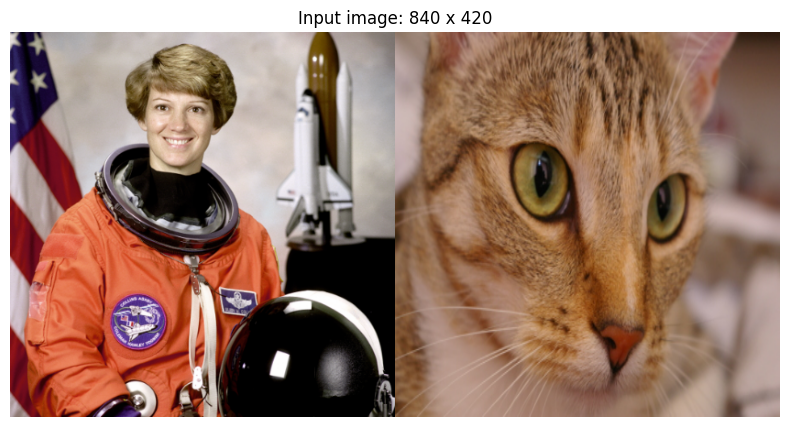

In [ ]:
astronaut = data.astronaut()
cat = data.chelsea()

astronaut = resize(
    astronaut, (420, 420),
    preserve_range=True,
    anti_aliasing=True
).astype(np.uint8)

cat = resize(
    cat, (420, 420),
    preserve_range=True,
    anti_aliasing=True
).astype(np.uint8)

image = np.concatenate([astronaut, cat], axis=1)

height, width = image.shape[:2]

print("Image shape:", image.shape)
print(f"Image dimensions: {width} x {height}")

plt.figure(figsize=(12, 5))
plt.imshow(image)
plt.title(f"Input image: {width} x {height}")
plt.axis("off")
plt.savefig("stage0_input.png", dpi=200, bbox_inches="tight")
plt.show()

# **3. Selective Search**


In [ ]:
start = time.perf_counter()

ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
ss.setBaseImage(cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
ss.switchToSelectiveSearchFast()

raw_proposals = ss.process()

proposal_time = time.perf_counter() - start

boxes = []

for x, y, w, h in raw_proposals:
    if w >= 32 and h >= 32:
        boxes.append([
            int(x),
            int(y),
            int(x + w),
            int(y + h)
        ])

boxes = np.asarray(boxes, dtype=np.int32)

print("Generated proposals:", len(raw_proposals))
print("Proposals after filtering:", len(boxes))
print(f"Selective Search time: {proposal_time:.3f} seconds")

assert len(boxes) >= 10, (
    "Unexpectedly few proposals. Check the input image and OpenCV."
)

Generated proposals: 2360
Proposals after filtering: 1331
Selective Search time: 6.155 seconds


# **4. Bounding Box Visualization**

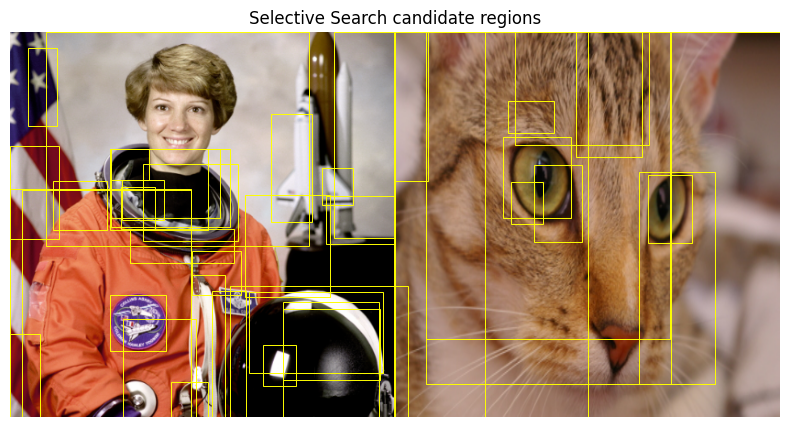

In [ ]:
def show_boxes(rgb, coordinates, title, max_boxes=40, filename=None):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.imshow(rgb)

    for x1, y1, x2, y2 in coordinates[:max_boxes]:
        ax.add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="yellow",
                linewidth=0.7
            )
        )

    ax.set_title(title)
    ax.axis("off")

    if filename is not None:
        plt.savefig(filename, dpi=200, bbox_inches="tight")

    plt.show()
    plt.close(fig)


show_boxes(
    image,
    boxes,
    "Selective Search candidate regions",
    max_boxes=45,
    filename="stage1_selective_search.png"
)

# **5. R-CNN**



Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 131MB/s]


R-CNN feature shape: (12, 576)
Time for 12 regions: 2.417 seconds


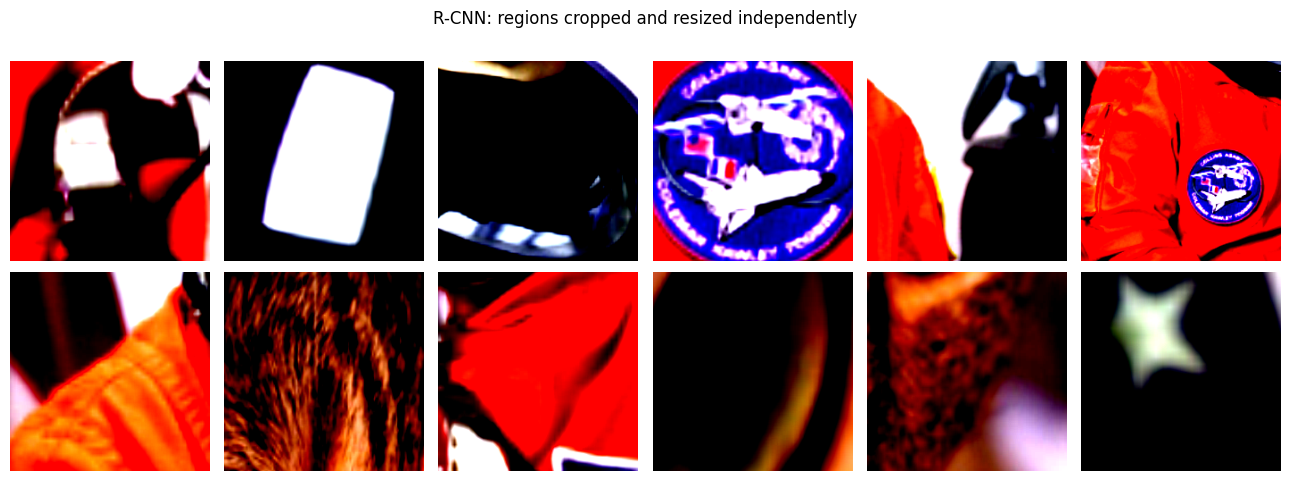

In [ ]:
mobilenet_weights = MobileNet_V3_Small_Weights.DEFAULT

mobilenet = mobilenet_v3_small(
    weights=mobilenet_weights
).to(device)

mobilenet.eval()

preprocess = mobilenet_weights.transforms()

feature_extractor = mobilenet.features
pool = torch.nn.AdaptiveAvgPool2d((1, 1))

def extract_crop_features(rgb, proposal_boxes):
    patches = []
    features_list = []

    start = time.perf_counter()

    with torch.inference_mode():
        for x1, y1, x2, y2 in proposal_boxes:
            x1 = max(0, int(x1))
            y1 = max(0, int(y1))
            x2 = min(rgb.shape[1], int(x2))
            y2 = min(rgb.shape[0], int(y2))

            crop = rgb[y1:y2, x1:x2]

            if crop.size == 0:
                continue

            pil_crop = Image.fromarray(crop)
            tensor_crop = preprocess(pil_crop).unsqueeze(0).to(device)

            feature_map = feature_extractor(tensor_crop)
            feature_vector = pool(feature_map).flatten(1)

            features_list.append(feature_vector.squeeze(0).cpu())
            patches.append(tensor_crop.squeeze(0).cpu())

    elapsed = time.perf_counter() - start

    if features_list:
        features_tensor = torch.stack(features_list)
    else:
        features_tensor = torch.empty((0, 576))

    return features_tensor, patches, elapsed


N = 12

rcnn_features, patches, rcnn_time = extract_crop_features(
    image,
    boxes[:N]
)

print("R-CNN feature shape:", tuple(rcnn_features.shape))
print(f"Time for {len(patches)} regions: {rcnn_time:.3f} seconds")

fig, axs = plt.subplots(2, 6, figsize=(13, 5))

for ax, patch in zip(axs.flat, patches):
    ax.imshow(patch.permute(1, 2, 0))
    ax.axis("off")

plt.suptitle("R-CNN: regions cropped and resized independently")
plt.tight_layout()
plt.savefig("stage2_rcnn_regions.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# **6. R-CNN Benchmarking**

In [ ]:
benchmark_results = []

for n in [12, 24]:
    features_n, patches_n, elapsed_n = extract_crop_features(
        image,
        boxes[:n]
    )

    benchmark_results.append({
        "Method": "Independent crop processing",
        "Number of regions": len(patches_n),
        "Feature shape": str(tuple(features_n.shape)),
        "Time (seconds)": elapsed_n
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

benchmark_df.to_csv(
    "rcnn_benchmark.csv",
    index=False
)

,Method,Number of regions,Feature shape,Time (seconds)
0,Independent crop processing,12,"(12, 576)",0.151733
1,Independent crop processing,24,"(24, 576)",0.332225


# **7. Fast R-CNN**

Shared feature map shape: (1, 576, 14, 27)
Shared feature extraction: 0.034 seconds


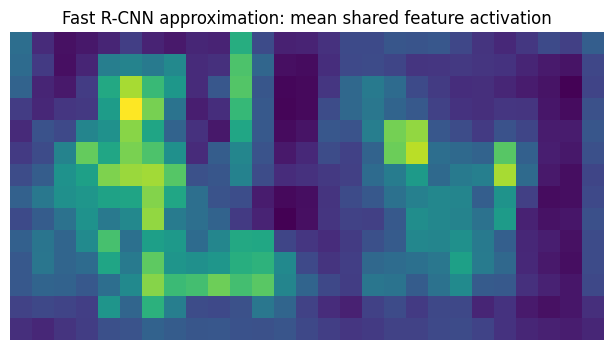

In [ ]:
image_tensor = (
    torch.from_numpy(image.copy())
    .permute(2, 0, 1)
    .float()
    .div(255.0)
    .unsqueeze(0)
    .to(device)
)

with torch.inference_mode():
    start = time.perf_counter()

    shared_map = feature_extractor(image_tensor)

    shared_time = time.perf_counter() - start

print("Shared feature map shape:", tuple(shared_map.shape))
print(f"Shared feature extraction: {shared_time:.3f} seconds")

fig, ax = plt.subplots(figsize=(11, 4))

ax.imshow(
    shared_map[0].mean(0).cpu().numpy(),
    cmap="viridis"
)

ax.set_title("Fast R-CNN approximation: mean shared feature activation")
ax.axis("off")

plt.savefig("stage3_fast_rcnn.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# **8. RoI Pooling**

In [ ]:
roi_boxes = torch.as_tensor(
    boxes[:12],
    dtype=torch.float32,
    device=device
)

# RoI Pool expects [batch_index, x1, y1, x2, y2].
roi_boxes_with_batch = torch.cat(
    [
        torch.zeros(
            (len(roi_boxes), 1),
            dtype=torch.float32,
            device=device
        ),
        roi_boxes
    ],
    dim=1
)

with torch.inference_mode():
    roi_features = roi_pool(
        shared_map,
        roi_boxes_with_batch,
        output_size=(7, 7),
        spatial_scale=1.0 / 32.0
    )

print("RoI Pool output shape:", tuple(roi_features.shape))

RoI Pool output shape: (12, 576, 7, 7)


# **9. Faster R-CNN**

In [ ]:
faster_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

faster_model = fasterrcnn_resnet50_fpn(
    weights=faster_weights
).to(device)

faster_model.eval()

categories = faster_weights.meta["categories"]

input_tensor = (
    torch.from_numpy(image.copy())
    .permute(2, 0, 1)
    .float()
    .div(255.0)
    .to(device)
)

with torch.inference_mode():
    start = time.perf_counter()
    faster_predictions = faster_model([input_tensor])[0]
    faster_time = time.perf_counter() - start

print("Output keys:", faster_predictions.keys())
print("Number of detections:", len(faster_predictions["boxes"]))
print(f"Inference time: {faster_time:.3f} seconds")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 124MB/s]


Output keys: dict_keys(['boxes', 'labels', 'scores'])
Number of detections: 22
Inference time: 0.691 seconds


# **10. Object Detection Visualization**

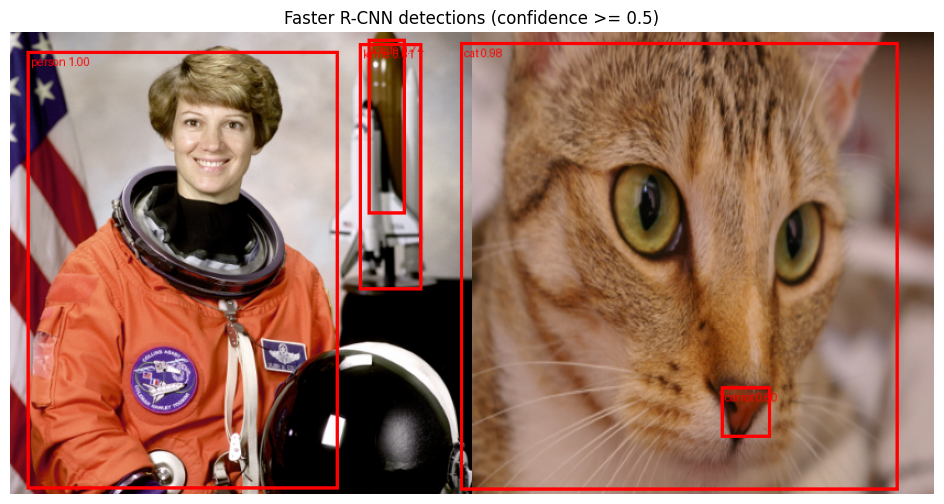

Detections at threshold 0.5: 5


In [ ]:
def visualize_detections(
    rgb,
    predictions,
    threshold=0.5,
    filename="stage4_faster_rcnn.png"
):
    keep = predictions["scores"] >= threshold

    final_boxes = (
        predictions["boxes"][keep]
        .round()
        .to(torch.int64)
        .cpu()
    )

    class_ids = predictions["labels"][keep].cpu().tolist()
    scores = predictions["scores"][keep].cpu().tolist()

    labels = [
        f"{categories[class_id]} {score:.2f}"
        for class_id, score in zip(class_ids, scores)
    ]

    image_uint8 = (
        torch.as_tensor(rgb.copy())
        .permute(2, 0, 1)
        .to(torch.uint8)
    )

    if len(final_boxes) > 0:
        rendered = draw_bounding_boxes(
            image_uint8,
            final_boxes,
            labels=labels,
            colors="red",
            width=3
        )
    else:
        rendered = image_uint8

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.imshow(rendered.permute(1, 2, 0))
    ax.set_title(
        f"Faster R-CNN detections (confidence >= {threshold})"
    )
    ax.axis("off")

    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    count = int(keep.sum())
    print(f"Detections at threshold {threshold}: {count}")

    return count


detection_count_05 = visualize_detections(
    image,
    faster_predictions,
    threshold=0.5,
    filename="stage4_faster_rcnn.png"
)

# **11. Confidence Threshold Analysis**

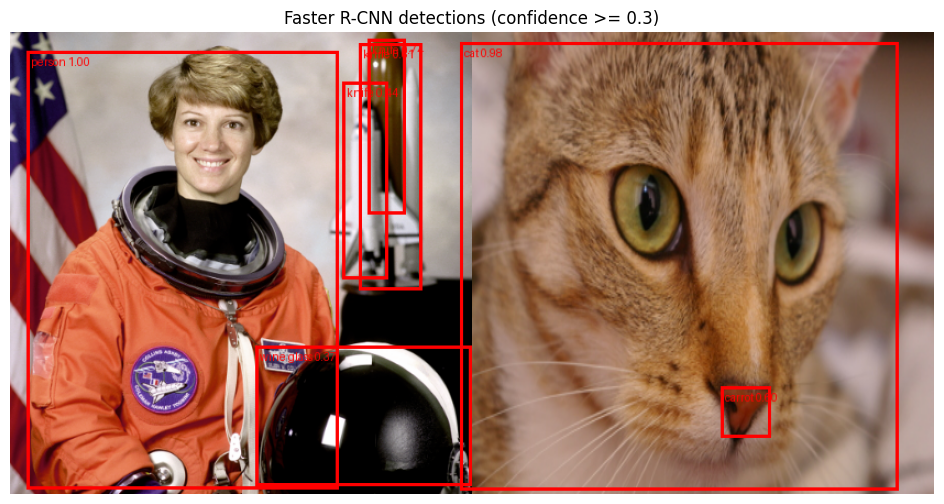

Detections at threshold 0.3: 7


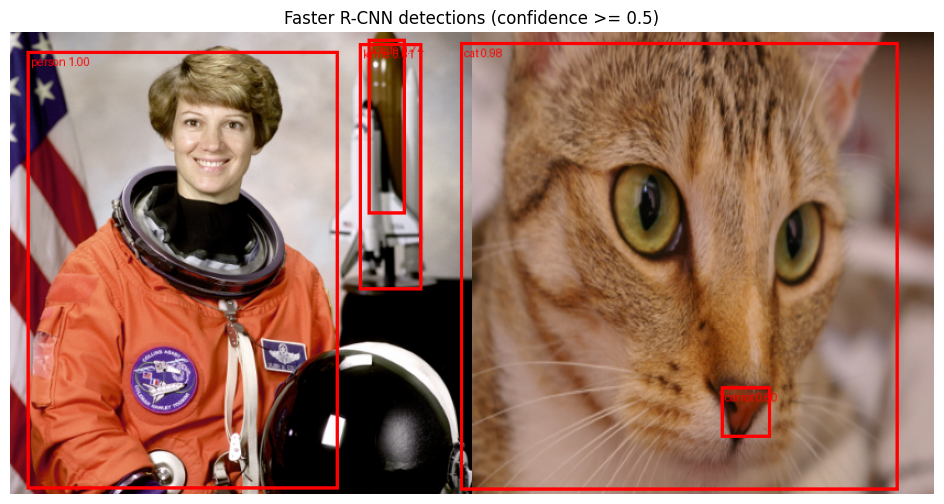

Detections at threshold 0.5: 5


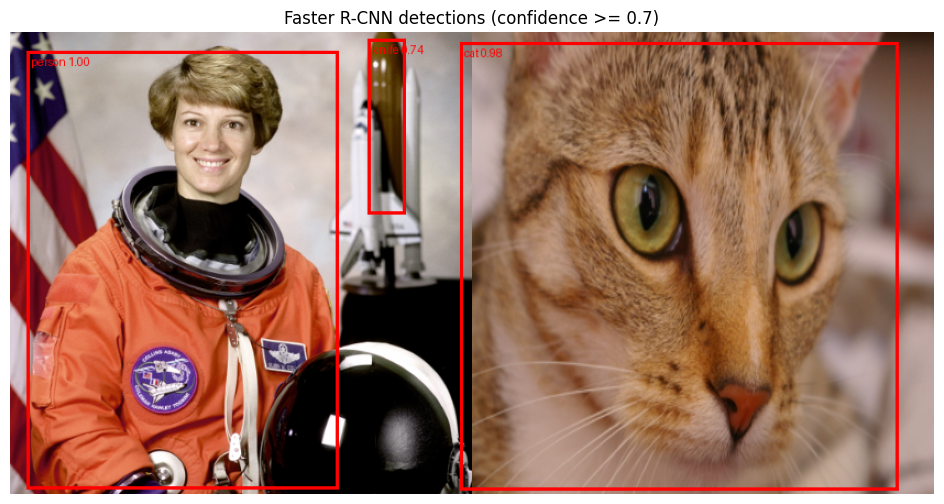

Detections at threshold 0.7: 3


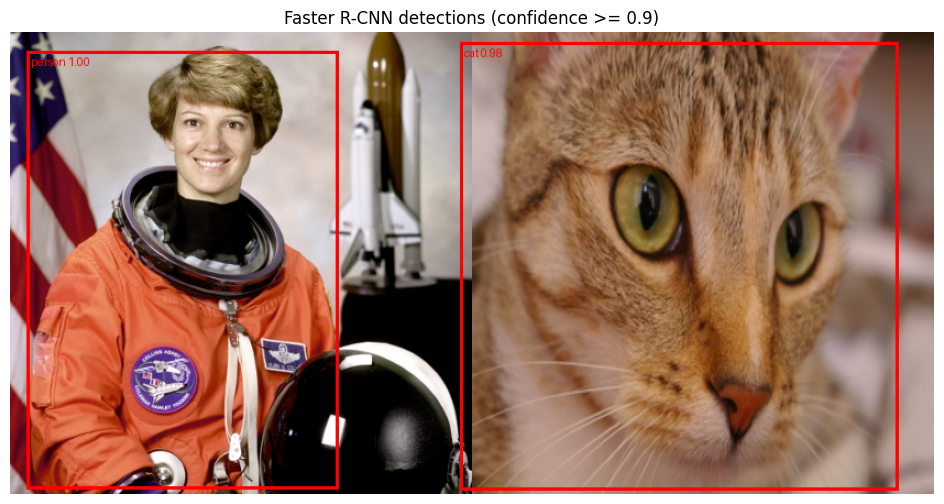

Detections at threshold 0.9: 2


,Confidence threshold,Number of detections
0,0.3,7
1,0.5,5
2,0.7,3
3,0.9,2


In [ ]:
threshold_results = []

for threshold in [0.3, 0.5, 0.7, 0.9]:
    count = visualize_detections(
        image,
        faster_predictions,
        threshold=threshold,
        filename=f"stage4_threshold_{threshold:.1f}.png"
    )

    threshold_results.append({
        "Confidence threshold": threshold,
        "Number of detections": count
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

threshold_df.to_csv(
    "confidence_threshold_results.csv",
    index=False
)

# **12. RPN and Anchors**

In [ ]:

with torch.inference_mode():
    image_list, _ = faster_model.transform([input_tensor], None)

    feature_maps = faster_model.backbone(image_list.tensors)

    if isinstance(feature_maps, torch.Tensor):
        feature_maps = {"0": feature_maps}

    # RPN expects a dictionary
    rpn_proposals, _ = faster_model.rpn(
        image_list,
        feature_maps,
        None
    )

    # Anchor generator expects a list of feature-map tensors
    feature_map_list = list(feature_maps.values())

    anchor_list = faster_model.rpn.anchor_generator(
        image_list,
        feature_map_list
    )


In [ ]:
transformed_height, transformed_width = image_list.image_sizes[0]

# **13. RoI Pooling vs. RoIAlign**

RoI Pooling shape: (12, 576, 7, 7)
RoIAlign shape: (12, 576, 7, 7)


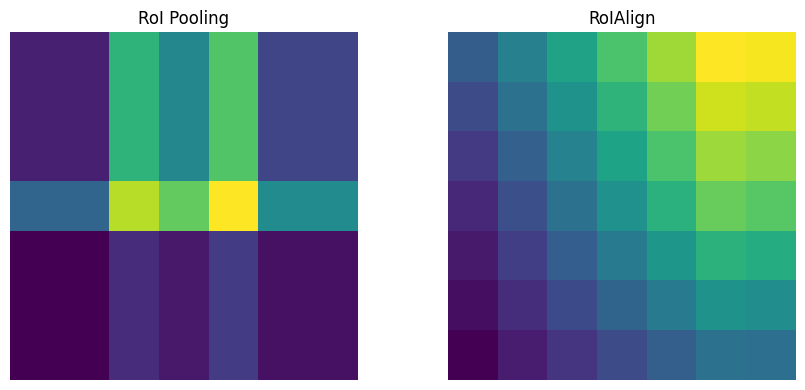

In [ ]:
with torch.inference_mode():
    aligned = roi_align(
        shared_map,
        roi_boxes_with_batch,
        output_size=(7, 7),
        spatial_scale=1.0 / 32.0,
        sampling_ratio=2,
        aligned=True
    )

print("RoI Pooling shape:", tuple(roi_features.shape))
print("RoIAlign shape:", tuple(aligned.shape))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    roi_features[0].mean(0).cpu().numpy(),
    cmap="viridis"
)
axes[0].set_title("RoI Pooling")

axes[1].imshow(
    aligned[0].mean(0).cpu().numpy(),
    cmap="viridis"
)
axes[1].set_title("RoIAlign")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "stage5_roi_pool_vs_align.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# **14. Mask R-CNN**



In [ ]:
mask_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

mask_model = maskrcnn_resnet50_fpn(
    weights=mask_weights
).to(device)

mask_model.eval()

with torch.inference_mode():
    start = time.perf_counter()
    mask_predictions = mask_model([input_tensor])[0]
    mask_time = time.perf_counter() - start

print("Output keys:", mask_predictions.keys())
print("Number of detections:", len(mask_predictions["boxes"]))
print("Masks shape:", tuple(mask_predictions["masks"].shape))
print(f"Mask R-CNN inference time: {mask_time:.3f} seconds")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 116MB/s]


Output keys: dict_keys(['boxes', 'labels', 'scores', 'masks'])
Number of detections: 29
Masks shape: (29, 1, 420, 840)
Mask R-CNN inference time: 0.297 seconds


# **15. Instance Mask Visualization**

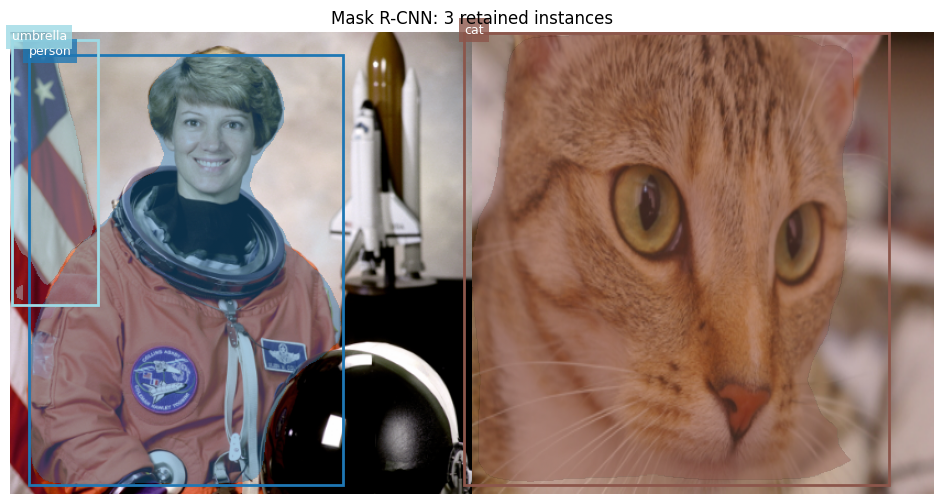

Instances displayed: 3


In [ ]:
def display_instance_masks(
    rgb,
    predictions,
    conf_threshold=0.5,
    mask_threshold=0.5,
    filename="stage5_mask_rcnn.png"
):
    selected_indices = torch.where(
        predictions["scores"] >= conf_threshold
    )[0][:12]

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.imshow(rgb)

    colors = plt.cm.tab20(
        np.linspace(0, 1, max(len(selected_indices), 1))
    )

    for color, index in zip(colors, selected_indices.tolist()):
        probability = (
            predictions["masks"][index, 0]
            .detach()
            .cpu()
            .numpy()
        )

        binary_mask = probability >= mask_threshold

        overlay = np.zeros((*binary_mask.shape, 4), dtype=float)
        overlay[binary_mask, :3] = color[:3]
        overlay[binary_mask, 3] = 0.4

        ax.imshow(overlay)

        x1, y1, x2, y2 = (
            predictions["boxes"][index]
            .detach()
            .cpu()
            .numpy()
        )

        ax.add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=color,
                linewidth=2
            )
        )

        label_id = int(predictions["labels"][index])
        label = categories[label_id]

        ax.text(
            x1,
            y1,
            label,
            color="white",
            fontsize=9,
            bbox={
                "facecolor": color,
                "alpha": 0.8,
                "edgecolor": "none"
            }
        )

    ax.axis("off")
    ax.set_title(
        f"Mask R-CNN: {len(selected_indices)} retained instances"
    )

    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Instances displayed:", len(selected_indices))


display_instance_masks(
    image,
    mask_predictions,
    conf_threshold=0.5,
    mask_threshold=0.5,
    filename="stage5_mask_rcnn.png"
)

# **16. Performance Comparison**

In [ ]:
comparison_df = pd.DataFrame([
    {
        "Method": "Selective Search",
        "Main operation": "Generate candidate regions",
        "Measured time (seconds)": proposal_time
    },
    {
        "Method": "R-CNN approximation (12 regions)",
        "Main operation": "CNN features for individual crops",
        "Measured time (seconds)": benchmark_df.iloc[0]["Time (seconds)"]
    },
    {
        "Method": "R-CNN approximation (24 regions)",
        "Main operation": "CNN features for individual crops",
        "Measured time (seconds)": benchmark_df.iloc[1]["Time (seconds)"]
    },
    {
        "Method": "Fast R-CNN approximation",
        "Main operation": "One shared feature map",
        "Measured time (seconds)": shared_time
    },
    {
        "Method": "Faster R-CNN",
        "Main operation": "RPN + object detection",
        "Measured time (seconds)": faster_time
    },
    {
        "Method": "Mask R-CNN",
        "Main operation": "Object detection + instance masks",
        "Measured time (seconds)": mask_time
    }
])

display(comparison_df)

comparison_df.to_csv(
    "rcnn_family_comparison.csv",
    index=False
)

,Method,Main operation,Measured time (seconds)
0,Selective Search,Generate candidate regions,6.154725
1,R-CNN approximation (12 regions),CNN features for individual crops,0.151733
2,R-CNN approximation (24 regions),CNN features for individual crops,0.332225
3,Fast R-CNN approximation,One shared feature map,0.034248
4,Faster R-CNN,RPN + object detection,0.690729
5,Mask R-CNN,Object detection + instance masks,0.297380
